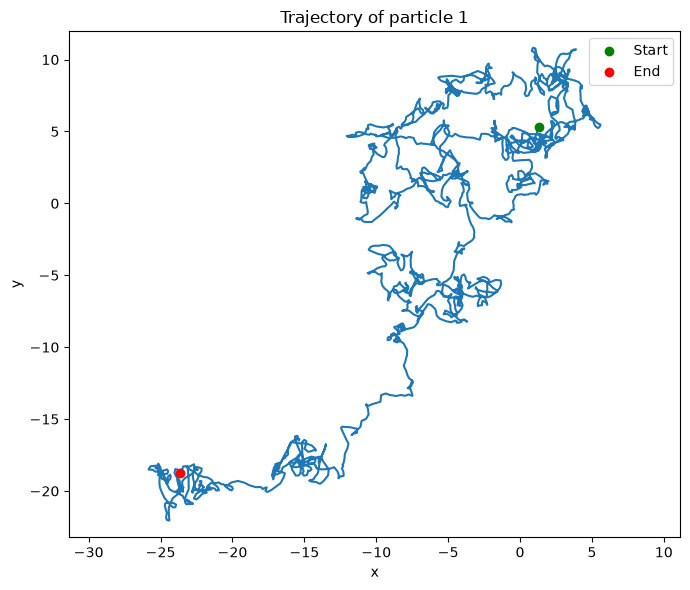

In [1]:
import matplotlib.pyplot as plt

TRAJ_FILE = "traj.lammpstrj"
MAIN_ID = 1  # Change to the atom ID of the main particle

positions = []
prev_wrapped = None
prev_unwrapped = None

with open(TRAJ_FILE, "r") as f:
    lines = f.readlines()

i = 0
while i < len(lines):
    if lines[i].strip() != "ITEM: TIMESTEP":
        i += 1
        continue

    timestep = int(lines[i + 1].strip())
    n_atoms = int(lines[i + 3].strip())
    xlo, xhi = map(float, lines[i + 5].split()[:2])
    ylo, yhi = map(float, lines[i + 6].split()[:2])
    lx, ly = xhi - xlo, yhi - ylo

    atom_header = lines[i + 8].strip().split()[2:]
    columns = {name: j for j, name in enumerate(atom_header)}
    atom_rows = lines[i + 9:i + 9 + n_atoms]

    x_col = "xu" if "xu" in columns else "x"
    y_col = "yu" if "yu" in columns else "y"
    has_unwrapped_coordinates = x_col == "xu" and y_col == "yu"

    for row in atom_rows:
        values = row.split()
        atom_id = int(values[columns["id"]])

        if atom_id != MAIN_ID:
            continue

        wrapped = (
            float(values[columns[x_col]]),
            float(values[columns[y_col]])
        )

        if has_unwrapped_coordinates or prev_wrapped is None:
            unwrapped = wrapped
        else:
            dx = wrapped[0] - prev_wrapped[0]
            dy = wrapped[1] - prev_wrapped[1]

            # Replace a periodic-boundary jump with the shortest displacement.
            dx -= lx * round(dx / lx)
            dy -= ly * round(dy / ly)

            unwrapped = (
                prev_unwrapped[0] + dx,
                prev_unwrapped[1] + dy
            )

        positions.append((timestep, *unwrapped))
        prev_wrapped = wrapped
        prev_unwrapped = unwrapped
        break

    i += 9 + n_atoms

if not positions:
    raise ValueError(f"Particle with id {MAIN_ID} was not found.")

positions.sort(key=lambda p: p[0])
timesteps, x, y = zip(*positions)

plt.figure(figsize=(7, 6))
plt.plot(x, y, "-", linewidth=1.5)
plt.scatter(x[0], y[0], color="green", label="Start", zorder=3)
plt.scatter(x[-1], y[-1], color="red", label="End", zorder=3)
plt.xlabel("x")
plt.ylabel("y")
plt.title(f"Trajectory of particle {MAIN_ID}")
plt.axis("equal")
plt.legend()
plt.tight_layout()
plt.show()

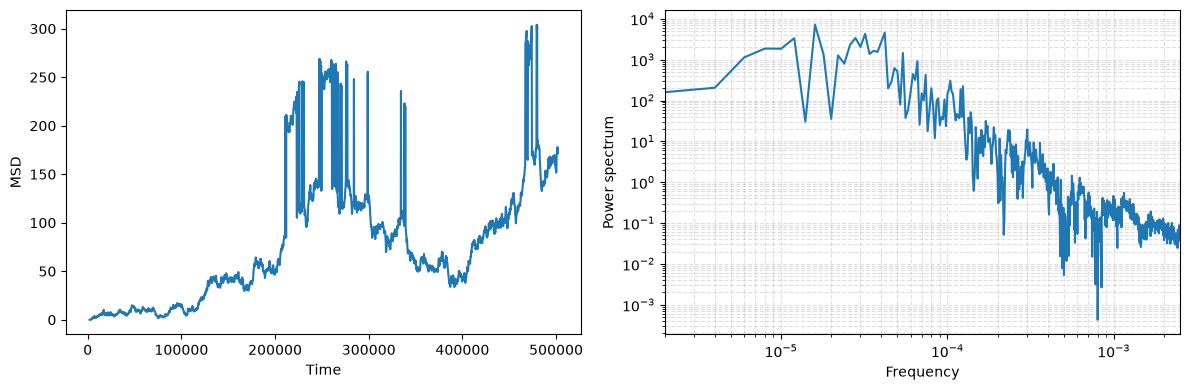

In [5]:
import numpy as np
from MDAnalysis import Universe

u = Universe("traj.lammpstrj", format="LAMMPSDUMP")
tracer_positions = []
trajectory_timesteps = []

for ts in u.trajectory:
    tracer_positions.append(u.select_atoms("type 1").positions[0].copy())
    trajectory_timesteps.append(ts.time)

tracer_positions = np.asarray(tracer_positions)
trajectory_timesteps = np.asarray(trajectory_timesteps)

# MSD
msd = np.mean((tracer_positions - tracer_positions[0]) ** 2, axis=1)

# Intermediate scattering function F(q,t) along x
q = 2 * np.pi / 5.0
r0 = tracer_positions[:, 0]
F = np.array([
    np.mean(np.cos(q * (r0[lag:] - r0[:len(r0) - lag])))
    for lag in range(len(r0))
])

# Power spectrum
S = np.abs(np.fft.rfft(F)) ** 2
dt = np.median(np.diff(trajectory_timesteps))
frequency = np.fft.rfftfreq(F.size, d=dt)

# The zero-frequency bin cannot be shown on a logarithmic x-axis.
valid = (frequency > 0) & np.isfinite(S) & (S > 0)

# Plotting the results
plt.figure(figsize=(12, 4))

plt.subplot(1, 2, 1)
plt.plot(trajectory_timesteps, msd)
plt.xlabel("Time")
plt.ylabel("MSD")

plt.subplot(1, 2, 2)
plt.loglog(frequency[valid], S[valid])
plt.xlabel("Frequency")
plt.ylabel("Power spectrum")
plt.xlim(frequency[valid].min(), frequency[valid].max())
plt.grid(True, which="both", linestyle="--", alpha=0.4)

plt.tight_layout()
plt.show()